# 07 — Two-parameter bifurcation analysis (checklist 3.7)

Convert validated one-parameter special points from Notebooks 05 (TTX) and 06
(ouabain / complete-TTX) into **bifurcation curves** in the biological plane

$$
(\alpha_I,\alpha_P)\in[0,1]^2.
$$

- Primary continuation plane: $(\alpha_I,\alpha_P)$
- PyCont types: **`H-C2`** (Hopf) and **`LP-C`** (equilibrium fold)
- Secondary $(g_I,I_{\mathrm{ep}})$ figure: **linear transform only** (no second continuation)
- Codimension-2 labels reported only when the installed software detects them

**Out of scope:** individual Jacobian / first-Lyapunov coefficient project
(`Notes/MATH3888_individual_component_jacobian_hopf_plan.md`); automatic
two-parameter LPC / HOM campaigns.

**Environment:** continuation engine
`scripts/run_07_two_parameter_bifurcation.py` is intended for Docker
(`curuy/math3888:latest`). This notebook loads saved CSVs/figures; set
`RERUN_CONTINUATION = True` only if you intentionally want a full recompute.


## 1. Aim and relation to one-parameter slices

Notebook 05 found a biological equilibrium fold **LP_bio** on the TTX-only
slice $\alpha_P=1$ at $\alpha_I\approx 0.614$, and no biological Hopf on
$\alpha_I\in[0,1]$.

Notebook 06 found, on the complete-TTX slice $\alpha_I=0$, two Hopfs on one
slow-orbit skeleton: **H_bio** at $\alpha_P\approx 0.268$ and **H_ext** at
$\alpha_P\approx 1.48$. Ouabain alone ($\alpha_I=1$) had **no** biological
Hopf/LP on the untreated-connected EP-C branch.

This notebook asks how those landmarks organise as curves in
$(\alpha_I,\alpha_P)$, and whether they meet at software-detected
codimension-2 points.


## 2. Imports / environment


In [1]:
import csv
import sys
from pathlib import Path

import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
import numpy as np

REPO_ROOT = Path.cwd().resolve()
if REPO_ROOT.name == "notebooks":
    REPO_ROOT = REPO_ROOT.parent
if str(REPO_ROOT) not in sys.path:
    sys.path.insert(0, str(REPO_ROOT))

from src.plant_kim_analysis import (
    G_I0,
    I_EP0,
    build_alpha_IP_vode_system,
    pars_from_alpha,
)
from src.plant_kim_model import STATE_VARS

FIGDIR = REPO_ROOT / "outputs" / "figures" / "two_parameter_bifurcation"
DATADIR = REPO_ROOT / "outputs" / "data" / "two_parameter_bifurcation"
FIGDIR.mkdir(parents=True, exist_ok=True)
DATADIR.mkdir(parents=True, exist_ok=True)

TTX_CSV = REPO_ROOT / "outputs" / "data" / "ttx_bifurcation" / "alphaI_epc_special_points.csv"
TTX0_CSV = (
    REPO_ROOT / "outputs" / "data" / "ouabain_bifurcation" / "ttx0_alphaP_epc_special_points.csv"
)

# Set True only to recompute H-C2 / LP-C in Docker (tens of minutes).
RERUN_CONTINUATION = False

print("REPO_ROOT:", REPO_ROOT)
print("G_I0 =", G_I0, "I_EP0 =", I_EP0)
print("FIGDIR:", FIGDIR)
print("DATADIR:", DATADIR)
print("RERUN_CONTINUATION:", RERUN_CONTINUATION)


REPO_ROOT: /Users/calvinlai/Desktop/MATH3888
G_I0 = 4.0 I_EP0 = -0.22
FIGDIR: /Users/calvinlai/Desktop/MATH3888/outputs/figures/two_parameter_bifurcation
DATADIR: /Users/calvinlai/Desktop/MATH3888/outputs/data/two_parameter_bifurcation
RERUN_CONTINUATION: False


## 3. Verify $\alpha_I$ / $\alpha_P$ mappings

Analysis-level scalings (canonical ODEs unchanged):

$$
g_I = \alpha_I\, G_{I0},\qquad I_{\mathrm{ep}} = \alpha_P\, I_{EP0},
$$

with $G_{I0}=4$ and $I_{EP0}=-0.22$. Joint ContClass helper
`build_alpha_IP_vode_system` freezes baseline $g_I$ and $I_{\mathrm{ep}}$ and
places both $\alpha$ factors in the voltage equation.


In [2]:
assert abs(G_I0 - 4.0) < 1e-15
assert abs(I_EP0 - (-0.22)) < 1e-15
assert abs(float(pars_from_alpha(1, 1)["g_I"]) - G_I0) < 1e-15
assert abs(float(pars_from_alpha(0, 1)["g_I"]) - 0.0) < 1e-15
assert abs(float(pars_from_alpha(1, 0)["I_ep"]) - 0.0) < 1e-15
assert abs(float(pars_from_alpha(1, 0.5)["I_ep"]) - 0.5 * I_EP0) < 1e-15

ode = build_alpha_IP_vode_system(alpha_I=0.0, alpha_P=0.268)
assert abs(float(ode.pars["g_I"]) - G_I0) < 1e-15
assert abs(float(ode.pars["I_ep"]) - I_EP0) < 1e-15
assert "alpha_I" in ode.pars and "alpha_P" in ode.pars
# Effective V equation uses alpha_I*g_I and alpha_P*I_ep
assert "alpha_I*g_I" in ode.funcspec.varspecs["V"]
assert "alpha_P*I_ep" in ode.funcspec.varspecs["V"]
print("Parameterisation / joint ContClass helper: PASS")
print("Biological square [0,1]^2 maps to g_I in [0,4], I_ep in [-0.22, 0]")


Parameterisation / joint ContClass helper: PASS
Biological square [0,1]^2 maps to g_I in [0,4], I_ep in [-0.22, 0]


## 4. Load validated one-parameter seed points

Seeds are read from Notebook 05/06 CSVs (not hard-coded).


In [3]:
def load_csv(path):
    with path.open(newline="") as f:
        return list(csv.DictReader(f))


def row_by_label(rows, label):
    for r in rows:
        if r.get("label") == label or r.get("report_label") == label:
            return r
    raise KeyError(label)


ttx_rows = load_csv(TTX_CSV)
ttx0_rows = load_csv(TTX0_CSV)
lp_bio = row_by_label(ttx_rows, "LP_bio")
h_bio = row_by_label(ttx0_rows, "H_bio")
h_ext = row_by_label(ttx0_rows, "H_ext")

print("LP_bio (NB05, alpha_P=1): alpha_I =", lp_bio["alpha_I"], "V =", lp_bio["V"])
print("H_bio (NB06 TTX0): alpha_P =", h_bio["alpha_P"], "V =", h_bio["V"])
print("H_ext (NB06 TTX0): alpha_P =", h_ext["alpha_P"], "V =", h_ext["V"])


LP_bio (NB05, alpha_P=1): alpha_I = 0.6141386577946849 V = -26.13422141940845
H_bio (NB06 TTX0): alpha_P = 0.2679201035441923 V = -44.79017270788987
H_ext (NB06 TTX0): alpha_P = 1.48030201106803 V = -49.90195002161819


## 5. Two-parameter continuation methodology

Installed PyCont types (Lab 7 / `ContClass.curve_list`):

| Purpose | `type` | `freepars` | Codim-2 if requested |
|---|---|---|---|
| Hopf curve | **`H-C2`** | `['alpha_I','alpha_P']` | BT, ZH, GH (`DH` not for H-C2) |
| LP / fold curve | **`LP-C`** | `['alpha_I','alpha_P']` | BT, ZH, CP |

Workflow used by the engine:

1. Build joint $\alpha$ VODE system.
2. Short `EP-C` on $\alpha_I=0$ (recover H1/H2) and on $\alpha_P=1$ (recover LP1).
3. `H-C2` from each Hopf, forward and backward.
4. `LP-C` from LP_bio, forward and backward.
5. Deduplicate overlapping segments / special points.
6. Cross-validate against NB05/06 anchors before interpretation.

Optional full recompute:


In [4]:
if RERUN_CONTINUATION:
    import runpy
    print("Re-running scripts/run_07_two_parameter_bifurcation.py ...")
    runpy.run_path(str(REPO_ROOT / "scripts" / "run_07_two_parameter_bifurcation.py"))
else:
    required = [
        "hopf_curve_dedup.csv",
        "lp_curve_dedup.csv",
        "slice_validation.csv",
        "codim2_special_points.csv",
        "stability_sample_points.csv",
    ]
    missing = [n for n in required if not (DATADIR / n).exists()]
    if missing:
        raise FileNotFoundError(
            "Missing two-parameter outputs: {}. Run "
            "`python scripts/run_07_two_parameter_bifurcation.py` in Docker, "
            "or set RERUN_CONTINUATION=True.".format(missing)
        )
    print("Using saved continuation outputs in", DATADIR)


Using saved continuation outputs in /Users/calvinlai/Desktop/MATH3888/outputs/data/two_parameter_bifurcation


## 6–8. Hopf continuation, deduplication, and comparison

Both complete-TTX Hopfs were continued with `H-C2`. The two seeds meet outside
the biological square near $(\alpha_I,\alpha_P)\approx(-2.91,\,1.33)$
(sample distance $\approx 0.004$), so they belong to **one physical Hopf
curve**. Inside $[0,1]^2$ the biologically relevant arc is the branch through
**H_bio**; the **H_ext** arc lies at $\alpha_P>1$ (mathematical exterior).


In [5]:
hopf = load_csv(DATADIR / "hopf_curve_dedup.csv")
hopf_note = (DATADIR / "hopf_dedup_note.txt").read_text()
print(hopf_note)
ai = np.array([float(r["alpha_I"]) for r in hopf])
ap = np.array([float(r["alpha_P"]) for r in hopf])
print("Hopf points:", len(hopf))
print("alpha_I range:", ai.min(), ai.max())
print("alpha_P range:", ap.min(), ap.max())
in_sq = ((ai >= 0) & (ai <= 1) & (ap >= 0) & (ap <= 1)).sum()
print("points in biological square:", int(in_sq))


H_bio and H_ext seeds lie on the SAME physical Hopf curve: the two continuations meet outside the biological square near (alpha_I, alpha_P) ≈ (-2.91, 1.33) (min sample distance ≈ 0.004). Deduplicated into one H_curve.
same_physical_curve=True

Hopf points: 878
alpha_I range: -3.1785752692750595 6.113153559269152
alpha_P range: -0.044375479702664755 1.5820000715084348
points in biological square: 145


## 9. LP continuation from TTX LP_bio

`LP-C` from LP_bio traces a fold curve that crosses $\alpha_P=1$ at the
validated TTX fold and continues through the biological square toward lower
$\alpha_P$ (exiting near $\alpha_P=0$).


In [6]:
lp = load_csv(DATADIR / "lp_curve_dedup.csv")
ai = np.array([float(r["alpha_I"]) for r in lp])
ap = np.array([float(r["alpha_P"]) for r in lp])
print("LP points:", len(lp))
print("alpha_I range:", ai.min(), ai.max())
print("alpha_P range:", ap.min(), ap.max())
in_sq = ((ai >= 0) & (ai <= 1) & (ap >= 0) & (ap <= 1)).sum()
print("points in biological square:", int(in_sq))


LP points: 437
alpha_I range: 0.3390775431618961 1.440151925488008
alpha_P range: -0.19858512432988648 6.017448410642021
points in biological square: 118


## 10. Codimension-2 special-point summary

On **H-C2**, LocBifPoints included BT, ZH, GH. On **LP-C**, BT, ZH, CP.

**Detected in this run:** two unique **ZH** (zero-Hopf / fold–Hopf) points on
the LP curve, both **outside** $[0,1]^2$:

- near $(\alpha_I,\alpha_P)\approx(1.12,\,3.97)$
- near $(\alpha_I,\alpha_P)\approx(0.345,\,-0.184)$

**Not detected:** GH, BT, CP.

Do **not** invent GH/BT/CP from visual curve crossings inside the square.
A nearby H–LP crossing without a software label remains an observation, not a
claimed Bogdanov–Takens point.


In [7]:
codim2 = load_csv(DATADIR / "codim2_special_points.csv")
print("Unique software-detected codim-2 points:")
if not codim2:
    print("  (none)")
for r in codim2:
    print(
        "  {type}  alpha_I={alpha_I}  alpha_P={alpha_P}  V={V}  "
        "parent={parent_curve}  bio_square={in_biological_square}".format(**r)
    )


Unique software-detected codim-2 points:
  ZH  alpha_I=1.121247943437301  alpha_P=3.9748702140418746  V=-23.725902830995782  parent=LP_from_LPbio  bio_square=False
  ZH  alpha_I=0.344902250306899  alpha_P=-0.18366872782506033  V=-31.205165869437693  parent=LP_from_LPbio  bio_square=False


### Conditional interpretation (only for detected types)

**ZH (zero-Hopf):** local interaction of a fold and a Hopf (pure imaginary pair
with a zero eigenvalue). Here both ZH points are exterior to the biological
square, so they organise mathematical skeleton rather than ordinary TTX/ouabain
doses.

**GH / BT / CP:** not labelled by PyCont in this campaign. No LPC follow-up is
forced. Individual Jacobian / Lyapunov work remains a separate optional project.


## 11. Slice cross-validation against Notebooks 05/06


In [8]:
val = load_csv(DATADIR / "slice_validation.csv")
print("curve | slice | target | status | details")
for r in val:
    extra = []
    for k in ("diff_alpha", "diff_V", "twoD_alpha_I", "twoD_alpha_P", "n_bio_alpha_P", "n_bio_alpha_I", "note"):
        if k in r and r[k] != "":
            extra.append(f"{k}={r[k]}")
    print(
        f"{r.get('curve')} | {r.get('slice')} | {r.get('target')} | {r.get('status')} | "
        + "; ".join(extra)
    )

gate = [
    r for r in val
    if r.get("target") in ("LP_bio", "H_bio") and r.get("status") != "PASS"
]
if gate:
    raise RuntimeError("Validation gate FAILED for LP_bio/H_bio — do not interpret map")
print("\nValidation gate (LP_bio, H_bio): PASS")


curve | slice | target | status | details
LP | alpha_P=1 | LP_bio | PASS | diff_alpha=0.0; diff_V=0.0; twoD_alpha_I=0.6141386577946849; twoD_alpha_P=1.0
H | alpha_I=0 | H_bio | PASS | diff_alpha=1.4214737942275235e-08; diff_V=7.190260475908872e-08; twoD_alpha_I=0.0; twoD_alpha_P=0.2679200893294544
H_from_Hext | alpha_I=0 | H_ext | PASS | diff_alpha=3.833407369313591e-09; diff_V=3.3693247303290264e-08; twoD_alpha_I=0.0; twoD_alpha_P=1.4803020072346227
H | alpha_I=1 | no_bio_H_expected | PASS | n_bio_alpha_P=0; note=NB06 ouabain-alone: no biological Hopf on untreated-connected branch
H | alpha_P=1 | no_bio_H_expected | PASS | n_bio_alpha_I=0; note=NB05 TTX-only: no biological Hopf in alpha_I in [0,1]

Validation gate (LP_bio, H_bio): PASS


## 12. Biological $(\alpha_I,\alpha_P)$ bifurcation map

Report-quality figures written by the continuation engine / post-process:


**Figure — $(\alpha_I,\alpha_P)$ map (modest exterior).** Biological square outlined. Red: Hopf curve (H_bio/H_ext seeds, same physical branch). Blue: LP curve from LP_bio. ZH markers only where software-detected.

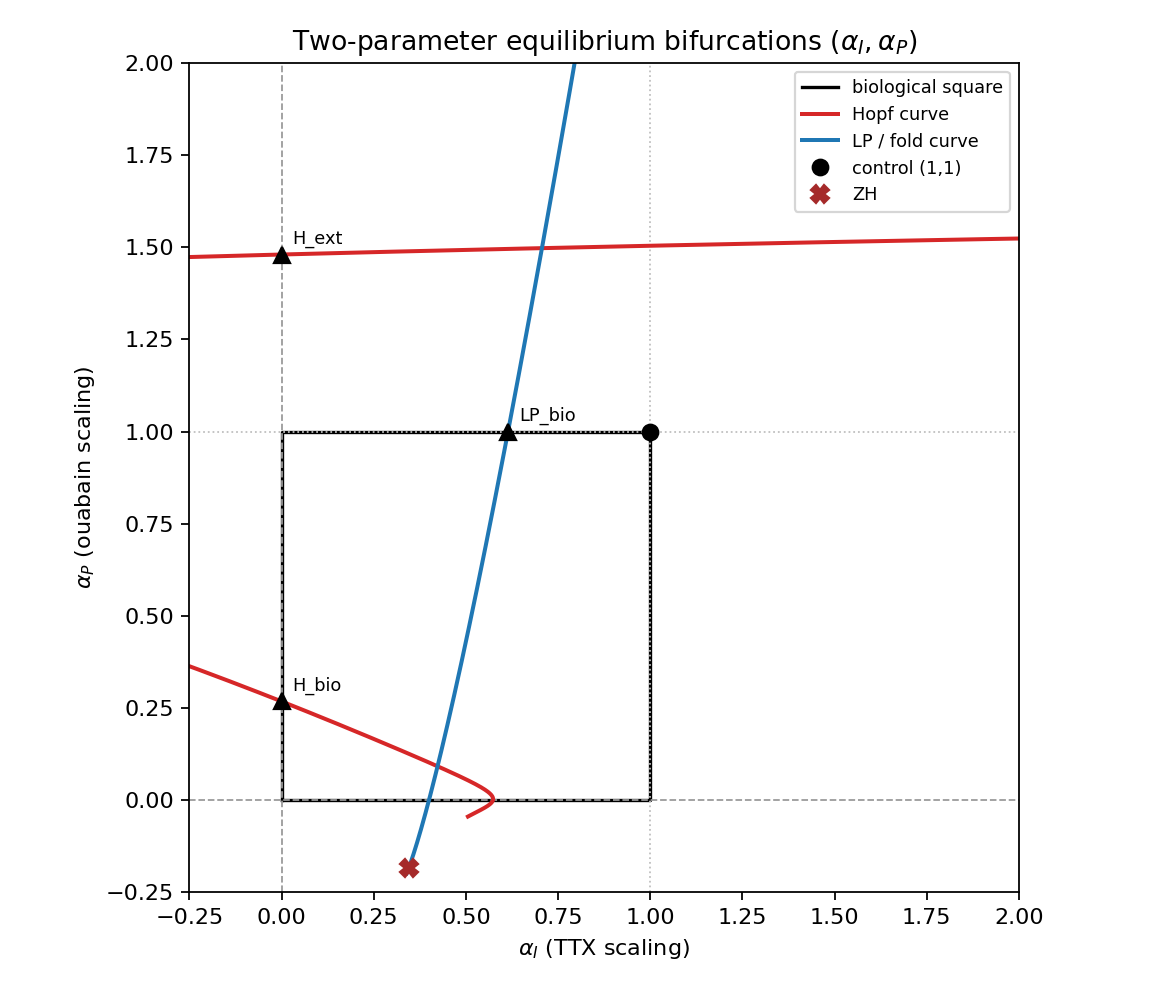

**Figure — biological square focus.** Hopf arc through H_bio stays at $\alpha_P\lesssim 0.27$ and reaches only to $\alpha_I\approx 0.57$ before leaving near $\alpha_P=0$. LP curve crosses $\alpha_P=1$ at LP_bio and traverses the square. Control $(1,1)$ lies to the right of the LP curve.

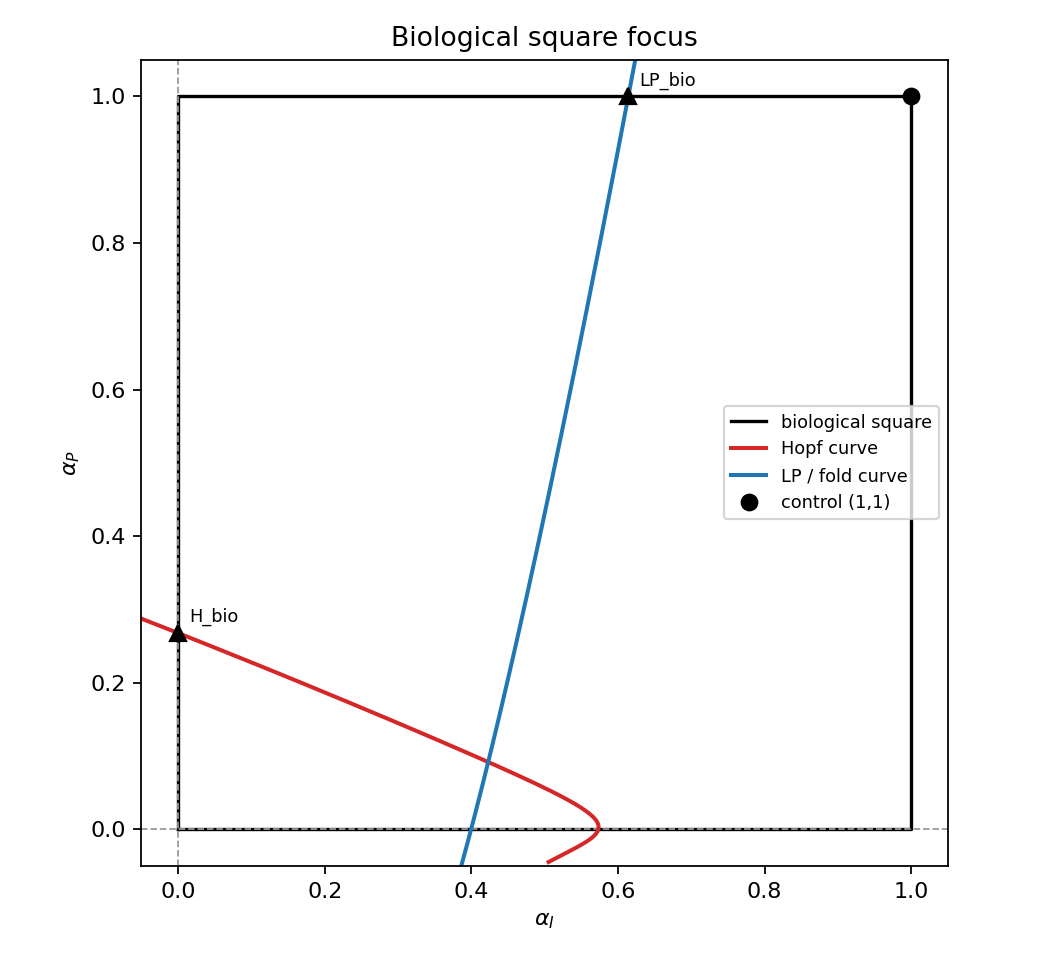

In [9]:
from IPython.display import Image, display, Markdown

for name, caption in [
    (
        "07_alphaIP_bifurcation_map.png",
        r"**Figure — $(\alpha_I,\alpha_P)$ map (modest exterior).** "
        r"Biological square outlined. Red: Hopf curve (H_bio/H_ext seeds, same physical branch). "
        r"Blue: LP curve from LP_bio. ZH markers only where software-detected.",
    ),
    (
        "07_alphaIP_biological_square.png",
        r"**Figure — biological square focus.** "
        r"Hopf arc through H_bio stays at $\alpha_P\lesssim 0.27$ and reaches only to "
        r"$\alpha_I\approx 0.57$ before leaving near $\alpha_P=0$. "
        r"LP curve crosses $\alpha_P=1$ at LP_bio and traverses the square. "
        r"Control $(1,1)$ lies to the right of the LP curve.",
    ),
]:
    path = FIGDIR / name
    display(Markdown(caption))
    display(Image(filename=str(path)))


**Figure — Biological square focus**

![07_alphaIP_biological_square.png](attachment:07_alphaIP_biological_square.png)

Hopf arc through $H_{\mathrm{bio}}$ stays at $\alpha_P\lesssim 0.27$ and reaches only to
$\alpha_I\approx 0.57$ near $\alpha_P=0$. LP curve crosses $\alpha_P=1$ at $LP_{\mathrm{bio}}$.
Control $(1,1)$ lies to the right of the LP curve. Do not claim BT from visual H–LP crossings.


**Figure — $(\alpha_I,\alpha_P)$ bifurcation map**

![07_alphaIP_bifurcation_map.png](attachment:07_alphaIP_bifurcation_map.png)

Biological square outlined. Red: Hopf curve (H_bio and H_ext seeds on one physical branch).
Blue: LP curve from LP_bio. ZH markers only where PyCont detected them (exterior).


In [10]:
# Cleaned report copy of 07_alphaIP_bifurcation_map.png, replaying the plotting code in
# scripts/run_07_two_parameter_bifurcation.py from the saved continuation CSVs.
# Geometry, limits and styles are unchanged; only title, legend and point labels differ.
from src.report_figures import clean_dir

A_I_LO, A_I_HI = -0.25, 2.0
A_P_LO, A_P_HI = -0.25, 2.0


def curve_segments_nan(rows):
    # The CSVs store forward/backward continuation segments back to back; NaN breaks
    # keep each segment separate (as in the original PNG) without spurious joins.
    xs, ys, prev = [], [], None
    for r in rows:
        if prev is not None and r["direction"] != prev:
            xs.append(np.nan)
            ys.append(np.nan)
        xs.append(float(r["alpha_I"]))
        ys.append(float(r["alpha_P"]))
        prev = r["direction"]
    return xs, ys


hopf_x, hopf_y = curve_segments_nan(load_csv(DATADIR / "hopf_curve_dedup.csv"))
lp_x, lp_y = curve_segments_nan(load_csv(DATADIR / "lp_curve_dedup.csv"))
all_codim2 = [
    {"type": r["type"], "alpha_I": float(r["alpha_I"]), "alpha_P": float(r["alpha_P"])}
    for r in load_csv(DATADIR / "codim2_special_points.csv")
]
anchors = {
    r"$LP_{\mathrm{bio}}$": (float(lp_bio["alpha_I"]), 1.0),
    r"$H_{\mathrm{bio}}$": (0.0, float(h_bio["alpha_P"])),
    r"$H_{\mathrm{ext}}$": (0.0, float(h_ext["alpha_P"])),
}

fig, ax = plt.subplots(figsize=(7.2, 6.2))
ax.plot([0, 1, 1, 0, 0], [0, 0, 1, 1, 0], "k-", lw=1.5, label="Biological region")
ax.axvline(0, color="0.6", ls="--", lw=0.8)
ax.axhline(0, color="0.6", ls="--", lw=0.8)
ax.axvline(1, color="0.75", ls=":", lw=0.8)
ax.axhline(1, color="0.75", ls=":", lw=0.8)
ax.plot(hopf_x, hopf_y, color="C3", lw=2.0, label="Hopf curve")
ax.plot(lp_x, lp_y, color="C0", lw=2.0, label="Fold curve")
ax.plot(1, 1, "ko", ms=7, label="Control $(1,1)$")
for lab, (x, y) in anchors.items():
    ax.plot(x, y, "k^", ms=7)
    ax.annotate(lab, (x, y), textcoords="offset points", xytext=(5, 5), fontsize=8)

codim2_markers = {"GH": "s", "BT": "D", "CP": "P", "ZH": "X"}
codim2_colors = {"GH": "darkorange", "BT": "purple", "CP": "green", "ZH": "brown"}
codim2_names = {"ZH": "Zero-Hopf (ZH)"}
seen_types = set()
for s in all_codim2:
    t = s["type"]
    if t not in codim2_markers:
        continue
    lab = codim2_names.get(t, t) if t not in seen_types else None
    seen_types.add(t)
    ax.plot(s["alpha_I"], s["alpha_P"], codim2_markers[t], color=codim2_colors[t], ms=8, label=lab, zorder=5)

ax.set_xlabel(r"$\alpha_I$ (TTX scaling)")
ax.set_ylabel(r"$\alpha_P$ (ouabain scaling)")
ax.set_xlim(A_I_LO, A_I_HI)
ax.set_ylim(A_P_LO, A_P_HI)
ax.set_title(r"Two-parameter bifurcation map in ($\alpha_I,\alpha_P$)")
ax.legend(loc="best", fontsize=8)
ax.set_aspect("equal", adjustable="box")
fig.tight_layout()
clean_path = clean_dir() / "alphaI_alphaP_bifurcation_map.png"
fig.savefig(clean_path, dpi=160)
plt.close(fig)
print("codim-2 types plotted:", sorted(seen_types))
print("saved", clean_path)

codim-2 types plotted: ['ZH']
saved /Users/calvinlai/Desktop/MATH3888/ReportFigs/cleaned/alphaI_alphaP_bifurcation_map.png


**Cleaned report figure — two-parameter bifurcation map in $(\alpha_I,\alpha_P)$.**

Report copy of `07_alphaIP_bifurcation_map.png`, redrawn from the saved continuation CSVs
(`hopf_curve_dedup.csv`, `lp_curve_dedup.csv`, `codim2_special_points.csv` and the NB05/NB06
special points) with the same geometry, limits and styles; only title, legend and point labels
are typeset. Each saved forward/backward continuation segment is drawn separately, as in the
original figure. The second detected ZH point, at $(\alpha_I,\alpha_P)\approx(1.12, 3.97)$, lies
outside the plotted window, as in the original. Saved to `ReportFigs/cleaned/`.

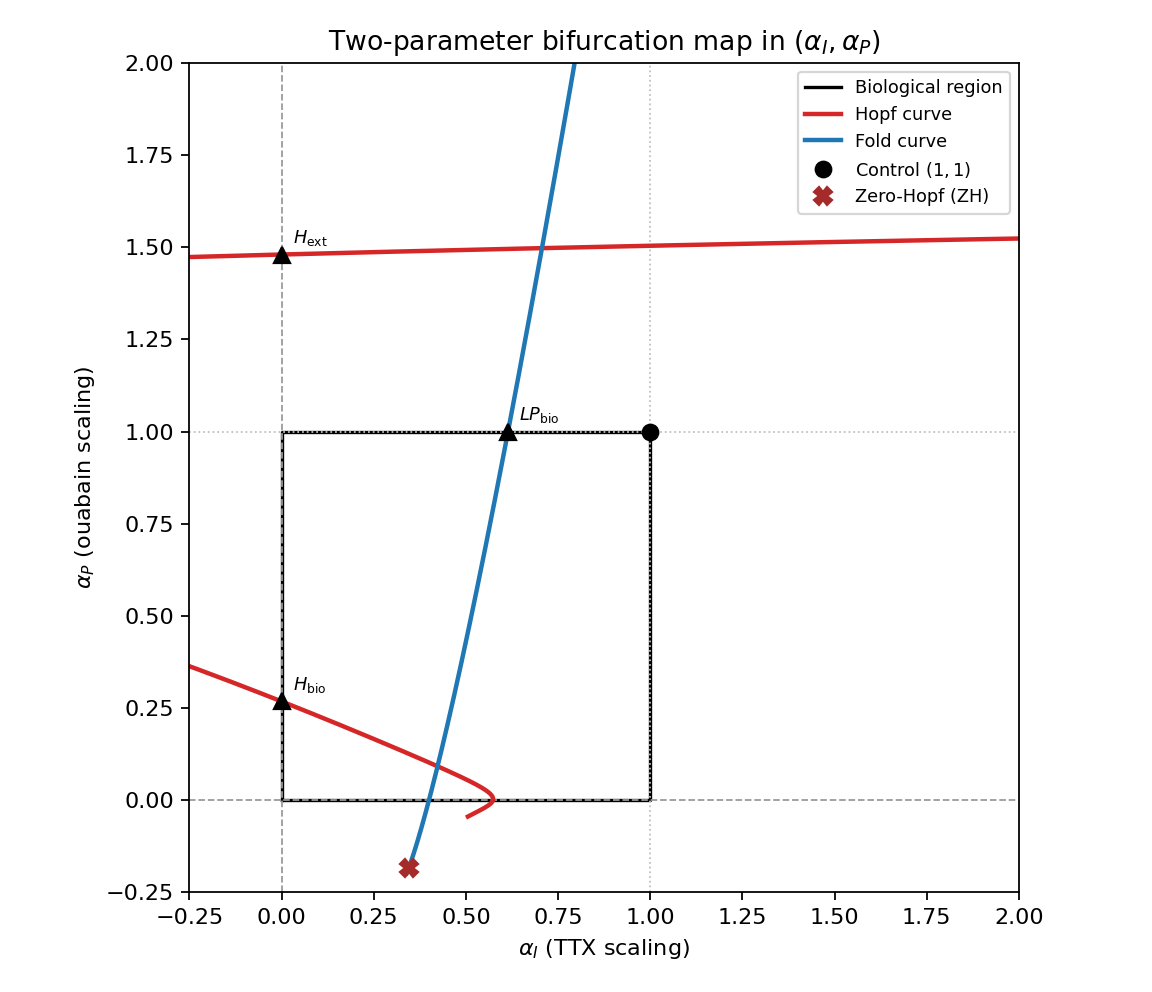


## 13. Representative equilibrium-stability regions

Sparse Jacobian checks (not a dense grid; not bursting/beating labels):


In [11]:
stab = load_csv(DATADIR / "stability_sample_points.csv")
print(f"{'name':22s} {'aI':>5s} {'aP':>5s} {'V*':>10s} {'stab':>12s} {'maxRe':>12s}")
for r in stab:
    V = float(r["V_star"]) if r.get("V_star") not in (None, "") else float("nan")
    mr = float(r["max_real_part"]) if r.get("max_real_part") not in (None, "") else float("nan")
    print(
        f"{r['name'][:22]:22s} {float(r['alpha_I']):5.2f} {float(r['alpha_P']):5.2f} "
        f"{V:10.3f} {r.get('stability','?'):>12s} {mr:12.4g}"
    )

print(
    "\nNotes: untreated/control has multiple accepted equilibria; the known "
    "bursting-related root near V*≈-18.3 mV is unstable. Combined corner (0,0) "
    "is stable — consistent with NB03. On alpha_I=0, alpha_P=0.15 (below H_bio) "
    "is stable while alpha_P=0.5 (between H_bio and H_ext) is unstable."
)


name                      aI    aP         V*         stab        maxRe
control                 1.00  1.00    -47.407     unstable    0.0003315
control_eq2             1.00  1.00    -33.341     unstable      0.06454
control_eq3             1.00  1.00    -18.312     unstable      0.01895
complete_TTX            0.00  1.00    -47.480     unstable    0.0002219
complete_ouabain        1.00  0.00    -17.188     unstable      0.01188
TTX_plus_ouabain        0.00  0.00    -42.812       stable   -0.0002716
TTX0_below_Hbio         0.00  0.15    -44.109       stable   -8.351e-05
TTX0_between_Hopfs      0.00  0.50    -45.779     unstable    0.0001047
TTX_partial_alphaP1     0.30  1.00    -47.458     unstable    0.0002532
TTX_mild_alphaP1        0.80  1.00    -47.422     unstable    0.0003084
TTX_mild_alphaP1_eq2    0.80  1.00    -31.449     unstable      0.06536
TTX_mild_alphaP1_eq3    0.80  1.00    -20.517     unstable      0.02383
mid_square              0.50  0.50    -45.702     unstable    0.

## 14. Transformed $(g_I,I_{\mathrm{ep}})$ map

Same continuation data under

$$
g_I = 4\,\alpha_I,\qquad I_{\mathrm{ep}} = -0.22\,\alpha_P.
$$

Because $I_{EP0}<0$, increasing $\alpha_P$ makes $I_{\mathrm{ep}}$ **more negative**.


**Figure — physical-parameter view.** Linear image of the biological square is $g_I\in[0,4]$, $I_{\mathrm{ep}}\in[-0.22,0]$. No new continuation was run.

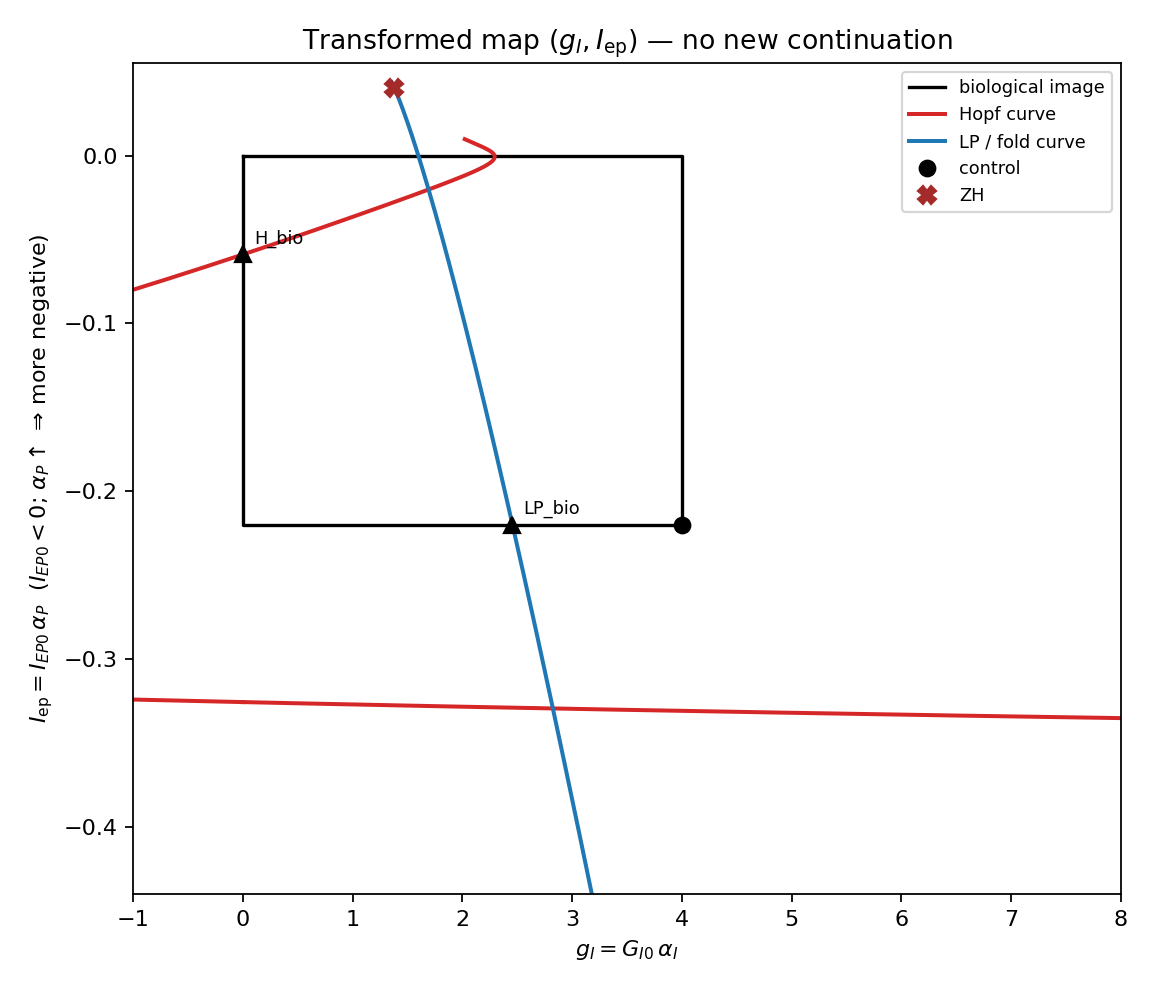

In [12]:
path = FIGDIR / "07_gI_Iep_transformed_map.png"
display(Markdown(
    r"**Figure — physical-parameter view.** Linear image of the biological square "
    r"is $g_I\in[0,4]$, $I_{\mathrm{ep}}\in[-0.22,0]$. No new continuation was run."
))
display(Image(filename=str(path)))


**Figure — Transformed $(g_I,I_{\mathrm{ep}})$ map**

![07_gI_Iep_transformed_map.png](attachment:07_gI_Iep_transformed_map.png)

Linear image of the same curves: $g_I=G_{I0}\alpha_I$, $I_{\mathrm{ep}}=I_{EP0}\alpha_P$ with
$I_{EP0}<0$ so $\alpha_P\uparrow$ makes $I_{\mathrm{ep}}$ more negative. No second continuation.


## 15. Interpretation for TTX / ouabain / combined drugs

1. **TTX fold as pump changes.** LP_bio continues as an LP curve through the
   biological square: the fold persists as $\alpha_P$ decreases, shifting
   mildly in $\alpha_I$. Combined blockade can cross this fold boundary.

2. **Complete-TTX Hopf as TTX is relaxed.** From H_bio, the Hopf curve moves to
   larger $\alpha_I$ while $\alpha_P$ falls, leaving the square near
   $\alpha_P\approx 0$ around $\alpha_I\approx 0.57$. It does **not** reach the
   ouabain-alone edge $\alpha_I=1$ inside $[0,1]$ — consistent with NB06 having
   no biological Hopf on that slice.

3. **Why Hopf at $\alpha_I=0$ but not at $\alpha_I=1$.** Geometry: the Hopf
   curve intersects $\alpha_I=0$ twice (H_bio, H_ext) but only H_bio is in
   $[0,1]$; the same curve never crosses $\alpha_I=1$ with $\alpha_P\in[0,1]$.

4. **Combined-drug path.** Decreasing $\alpha_P$ at $\alpha_I=0$ crosses H_bio
   (unstable→stable), matching NB03/NB06. Paths with partial TTX may instead
   meet the LP curve depending on dose combination.

5. **Codim-2.** Only exterior ZH points were labelled; no GH/BT/CP inside the
   drug square. Visual H–LP proximity inside the square is **not** claimed as BT.


## 16. Numerical limitations

- `H-C2` / `LP-C` are not AUTO-gated; still run in Docker for stack parity with NB05/06.
- Forward/backward and multi-seed continuations can retrace the same branch; dedup is required.
- `MX` is numerical termination, not a bifurcation.
- Period / LC structure is **not** re-continued here; GH→LPC would be a focused follow-up if GH appeared.
- Stability samples use accepted current-balance roots; multiple equilibria can coexist near folds.


## 17. Summary and saved outputs

| Output | Path |
|---|---|
| Hopf raw / dedup | `outputs/data/two_parameter_bifurcation/hopf_*.csv` |
| LP raw / dedup | `outputs/data/two_parameter_bifurcation/lp_*.csv` |
| Codim-2 | `.../codim2_special_points.csv` |
| Slice validation | `.../slice_validation.csv` |
| Stability samples | `.../stability_sample_points.csv` |
| Figures | `outputs/figures/two_parameter_bifurcation/` |
| Engine | `scripts/run_07_two_parameter_bifurcation.py` |

**Verdict.** One physical Hopf curve (H_bio↔H_ext) and one LP curve (from LP_bio)
organise the biological square; slice anchors reproduce NB05/06 to continuation
tolerance; software-detected codim-2 points are exterior ZH only.
